In [1]:
# Imports and reproducibility
import os, shutil, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    classification_report, confusion_matrix, accuracy_score,
    precision_score, recall_score, f1_score, roc_auc_score,
    average_precision_score
)
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
print("TensorFlow:", tf.__version__)
GPUS = tf.config.list_physical_devices("GPU")
print("GPU(s):", GPUS if GPUS else "No GPU detected; CPU training will be slower.")
for gpu in GPUS:
    try: tf.config.experimental.set_memory_growth(gpu, True)
    except Exception as e: print("GPU memory growth:", e)
# Mixed precision can accelerate compatible NVIDIA GPUs.
if GPUS:
    from tensorflow.keras import mixed_precision
    mixed_precision.set_global_policy("mixed_float16")
    print("Precision policy:", mixed_precision.global_policy())

TensorFlow: 2.21.0
GPU(s): No GPU detected; CPU training will be slower.


In [2]:
# Mount Google Drive
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [3]:
# Locate the project and dataset. Supports common folder-name variations.
MY_DRIVE = '/content/drive/MyDrive'
PROJECT_CANDIDATES = [
    os.path.join(MY_DRIVE, 'Brain_Tumor_CNN_Project'),
    os.path.join(MY_DRIVE, 'brain_tumor'),
]
PROJECT_DIR = next((p for p in PROJECT_CANDIDATES if os.path.isdir(os.path.join(p, 'results'))), None)
if PROJECT_DIR is None:
    PROJECT_DIR = next((p for p in PROJECT_CANDIDATES if os.path.isdir(p)), None)
if PROJECT_DIR is None:
    raise FileNotFoundError('Could not find project folder. Check the folder name under My Drive.')

RESULTS_DIR = os.path.join(PROJECT_DIR, 'results')
MODEL_DIR = os.path.join(PROJECT_DIR, 'models')
MODELS_DIR = MODEL_DIR  # alias used throughout this notebook
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)

In [4]:
DATASET_CANDIDATES = [
    os.path.join(PROJECT_DIR, 'dataset', 'Epic and CSCR hospital Dataset'),
    os.path.join(PROJECT_DIR, 'dataset', 'Epic and CSCR hospital Dataset-zip'),
    os.path.join(PROJECT_DIR, 'dataset'),
    os.path.join(MY_DRIVE, 'brain_tumor', 'dataset', 'Epic and CSCR hospital Dataset'),
    os.path.join(MY_DRIVE, 'brain_tumor', 'dataset', 'Epic and CSCR hospital Dataset-zip'),
]
DRIVE_DATASET_DIR = next((p for p in DATASET_CANDIDATES if os.path.isdir(os.path.join(p, 'Train')) and os.path.isdir(os.path.join(p, 'Test'))), None)
if DRIVE_DATASET_DIR is None:
    DRIVE_DATASET_DIR = next((p for p in DATASET_CANDIDATES if os.path.isdir(p) and os.path.basename(p) != 'dataset'), None)
if DRIVE_DATASET_DIR is None:
    raise FileNotFoundError('Could not locate the extracted dataset folder. Check the dataset path in Google Drive.')

In [5]:
# Copy dataset to the runtime SSD only once. This copy disappears when the runtime resets.
LOCAL_DATASET_DIR = '/content/brain_tumor_dataset'
if os.path.abspath(DRIVE_DATASET_DIR) != os.path.abspath(LOCAL_DATASET_DIR):
    if not os.path.isdir(LOCAL_DATASET_DIR):
        print('Copying dataset to Colab local storage; first copy may take a while...')
        shutil.copytree(DRIVE_DATASET_DIR, LOCAL_DATASET_DIR)
        print('Local copy complete.')
    else:
        print('Reusing existing local dataset copy.')
DATASET_DIR = LOCAL_DATASET_DIR
print('Project:', PROJECT_DIR)
print('Dataset source:', DRIVE_DATASET_DIR)
print('Local dataset:', DATASET_DIR)
print('Results:', RESULTS_DIR)
print('Models:', MODELS_DIR)

Copying dataset to Colab local storage; first copy may take a while...
Local copy complete.
Project: /content/drive/MyDrive/Brain_Tumor_CNN_Project
Dataset source: /content/drive/MyDrive/Brain_Tumor_CNN_Project/dataset/Epic and CSCR hospital Dataset
Local dataset: /content/brain_tumor_dataset
Results: /content/drive/MyDrive/Brain_Tumor_CNN_Project/results
Models: /content/drive/MyDrive/Brain_Tumor_CNN_Project/models


In [6]:
# Locate split CSVs (the notebook expects pre-created train/validation/test splits).
def find_csv(candidates):
    for path in candidates:
        if os.path.isfile(path):
            return path
    return None

train_csv = find_csv([
    os.path.join(RESULTS_DIR, 'train_split.csv'),
    os.path.join(RESULTS_DIR, 'train.csv'),
])
val_csv = find_csv([
    os.path.join(RESULTS_DIR, 'validation_split.csv'),
    os.path.join(RESULTS_DIR, 'val_split.csv'),
    os.path.join(RESULTS_DIR, 'validation.csv'),
])
test_csv = find_csv([
    os.path.join(RESULTS_DIR, 'test_split.csv'),
    os.path.join(RESULTS_DIR, 'test.csv'),
])
if not all([train_csv, val_csv, test_csv]):
    raise FileNotFoundError(
        'Missing split CSV(s). Expected train_split.csv, validation_split.csv (or val_split.csv), '
        'and test_split.csv inside: ' + RESULTS_DIR)

In [7]:
train_df = pd.read_csv(train_csv)
val_df = pd.read_csv(val_csv)
test_df = pd.read_csv(test_csv)
for name, df in [('train', train_df), ('validation', val_df), ('test', test_df)]:
    if not {'image_path', 'label'}.issubset(df.columns):
        raise ValueError(f'{name} CSV must contain columns image_path and label; found {df.columns.tolist()}')
    df['label'] = pd.to_numeric(df['label'], errors='raise').astype('int32')
    if not set(df['label'].unique()).issubset({0, 1}):
        raise ValueError(f'{name} labels must be encoded as 0 and 1 for binary classification.')

print(f'Train: {len(train_df):,} | Validation: {len(val_df):,} | Test: {len(test_df):,}')

Train: 4,844 | Validation: 1,930 | Test: 2,093


In [8]:
# Resolve CSV image paths to the local copy where possible, then verify ALL splits.
# Relative paths are preserved; basename fallback is used only if it is unambiguous.
local_files = {}
for root, _, files in os.walk(DATASET_DIR):
    for filename in files:
        if filename.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.webp')):
            local_files.setdefault(filename, []).append(os.path.join(root, filename))

source_root = os.path.abspath(DRIVE_DATASET_DIR)
local_root = os.path.abspath(DATASET_DIR)
def resolve_local_path(raw_path):
    raw_path = str(raw_path)
    if os.path.isfile(raw_path) and os.path.abspath(raw_path).startswith(local_root + os.sep):
        return raw_path
    # Map a path under the original dataset root to the same relative path locally.
    try:
        rel = os.path.relpath(os.path.abspath(raw_path), source_root)
        candidate = os.path.join(local_root, rel)
        if os.path.isfile(candidate):
            return candidate
    except Exception:
        pass
    # If the CSV uses an older project root, preserve the Train/Test/class/file suffix.
    parts = Path(raw_path).parts
    lower_parts = [part.lower() for part in parts]
    marker_idx = next((i for i, part in enumerate(lower_parts) if part in ('train', 'test', 'validation', 'val')), None)
    if marker_idx is not None:
        candidate = os.path.join(local_root, *parts[marker_idx:])
        if os.path.isfile(candidate):
            return candidate
        # Dataset may be nested one level below the copied directory.
        for nested_root, _, _ in os.walk(local_root):
            candidate = os.path.join(nested_root, *parts[marker_idx:])
            if os.path.isfile(candidate):
                return candidate
    # CSVs sometimes contain paths from an older Drive/project location.
    matches = local_files.get(os.path.basename(raw_path), [])
    if len(matches) == 1:
        return matches[0]
    # Keep original path so the validation below reports it clearly.
    return raw_path

In [9]:
for df in (train_df, val_df, test_df):
    df['image_path'] = df['image_path'].map(resolve_local_path)

for name, df in [('train', train_df), ('validation', val_df), ('test', test_df)]:
    missing = [p for p in df['image_path'] if not os.path.isfile(p)]
    print(f'{name}: {len(missing)} missing image path(s)')
    if missing:
        raise FileNotFoundError('Example missing image path(s):\n' + '\n'.join(map(str, missing[:5])))

CLASS_NAMES = ['Non-Tumourous', 'Tumourous']
print('Image paths verified and mapped to local storage where possible.')

train: 0 missing image path(s)
validation: 0 missing image path(s)
test: 0 missing image path(s)
Image paths verified and mapped to local storage where possible.


In [10]:
# ResNet50 preprocessing and fast tf.data pipeline
# ResNet50 preprocess_input converts RGB pixels to BGR and zero-centers channels.
# Do not divide by 255 before calling preprocess_input.
IMG_SIZE = (224, 224)
BATCH_SIZE = 32 if GPUS else 8
AUTOTUNE = tf.data.AUTOTUNE
from tensorflow.keras.applications.resnet50 import preprocess_input

def preprocess_image(image_path, label):
    image_bytes = tf.io.read_file(image_path)
    image = tf.io.decode_image(image_bytes, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE, antialias=False)
    image = tf.cast(image, tf.float32)
    image = preprocess_input(image)
    return image, tf.cast(label, tf.float32)

def make_dataset(df, training=False):
    paths = df["image_path"].astype(str).to_numpy()
    labels = df["label"].astype("float32").to_numpy()
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(min(len(df), 2048), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(preprocess_image, num_parallel_calls=AUTOTUNE, deterministic=not training)
    ds = ds.batch(BATCH_SIZE, drop_remainder=False)
    return ds.prefetch(AUTOTUNE)

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)
print("Samples:", len(train_df), len(val_df), len(test_df))
print("Batches:", tf.data.experimental.cardinality(train_ds).numpy(),
      tf.data.experimental.cardinality(val_ds).numpy(),
      tf.data.experimental.cardinality(test_ds).numpy())
xb, yb = next(iter(train_ds))
print("Image batch:", xb.shape, "labels:", yb.shape)
print("Preprocessed pixel range:", float(tf.reduce_min(xb)), "to", float(tf.reduce_max(xb)))

Samples: 4844 1930 2093
Batches: 606 242 262
Image batch: (8, 224, 224, 3) labels: (8,)
Preprocessed pixel range: -123.68000030517578 to 146.06100463867188


In [11]:
# Class weights from training data only
y_train = train_df["label"].to_numpy().astype(int)
classes = np.unique(y_train)
if not np.array_equal(classes, np.array([0, 1])):
    raise ValueError(f"Training split must contain both labels 0 and 1; found {classes}")
weights = compute_class_weight(class_weight="balanced", classes=classes, y=y_train)
class_weights = {int(k): float(v) for k, v in zip(classes, weights)}
CLASS_NAMES = ["Non-Tumourous", "Tumourous"]
print("Class weights:", class_weights)
print("Verify label mapping: 0=Non-Tumourous, 1=Tumourous")

Class weights: {0: 3.5881481481481483, 1: 0.580954665387383}
Verify label mapping: 0=Non-Tumourous, 1=Tumourous


In [12]:
# Build ResNet50 transfer-learning model
from tensorflow.keras import layers

base_model = tf.keras.applications.ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(*IMG_SIZE, 3)
)
base_model.trainable = False

inputs = layers.Input(shape=(*IMG_SIZE, 3), name="image")
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D(name="global_average_pooling")(x)
x = layers.Dropout(0.30, name="head_dropout")(x)
outputs = layers.Dense(1, activation="sigmoid", dtype="float32", name="tumour_probability")(x)
model = tf.keras.Model(inputs, outputs, name="ResNet50_BrainTumour")
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)
model.summary()
print("Total parameters:", model.count_params())
print("Trainable parameters:", sum(int(tf.size(v)) for v in model.trainable_variables))

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "ResNet50_BrainTumour"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head_dropout (Dropout)          │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ tumour_probability (Dense)      │ (None, 1)              │         2,049 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,589,761 (89.99 MB)

 Trainable params: 2,049 (8.00 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

Total parameters: 23589761
Trainable parameters: 2049


In [13]:
# Train Phase 1: frozen ResNet50 backbone
BEST_PATH = os.path.join(MODELS_DIR, "best_resnet50.keras")
PHASE1_PATH = os.path.join(MODELS_DIR, "resnet50_phase1_best.keras")
callbacks1 = [
    tf.keras.callbacks.ModelCheckpoint(PHASE1_PATH, monitor="val_loss", save_best_only=True, verbose=1),
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.2, patience=1, min_lr=1e-7, verbose=1)
]
start = time.time()
history_p1 = model.fit(
    train_ds, validation_data=val_ds, epochs=5,
    class_weight=class_weights, callbacks=callbacks1, verbose=1
)
phase1_seconds = time.time() - start
print(f"Phase 1: {phase1_seconds/60:.2f} minutes")

Epoch 1/5
606/606 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8275 - auc: 0.8843 - loss: 0.4012 - precision: 0.9562 - recall: 0.8357
Epoch 1: val_loss improved from None to 0.12782, saving model to /content/drive/MyDrive/Brain_Tumor_CNN_Project/models/resnet50_phase1_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Brain_Tumor_CNN_Project/models/resnet50_phase1_best.keras
606/606 ━━━━━━━━━━━━━━━━━━━━ 1090s 2s/step - accuracy: 0.8966 - auc: 0.9606 - loss: 0.2540 - precision: 0.9786 - recall: 0.8995 - val_accuracy: 0.9591 - val_auc: 0.9919 - val_loss: 0.1278 - val_precision: 0.9919 - val_recall: 0.9565 - learning_rate: 0.0010
Epoch 2/5
606/606 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9536 - auc: 0.9861 - loss: 0.1309 - precision: 0.9921 - recall: 0.9536
Epoch 2: val_loss improved from 0.12782 to 0.08164, saving model to /content/drive/MyDrive/Brain_Tumor_CNN_Project/models/resnet50_phase1_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Brai

In [14]:
# Fine-tune only the final 20 non-BatchNorm layers (optional)
RUN_FINE_TUNING = True
history_p2 = None
phase2_seconds = 0.0

if RUN_FINE_TUNING:
    base_model.trainable = True
    for layer in base_model.layers[:-20]:
        layer.trainable = False
    for layer in base_model.layers:
        if isinstance(layer, tf.keras.layers.BatchNormalization):
            layer.trainable = False

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
        loss="binary_crossentropy",
        metrics=[
            tf.keras.metrics.BinaryAccuracy(name="accuracy"),
            tf.keras.metrics.Precision(name="precision"),
            tf.keras.metrics.Recall(name="recall"),
            tf.keras.metrics.AUC(name="auc")
        ]
    )
    callbacks2 = [
        tf.keras.callbacks.ModelCheckpoint(BEST_PATH, monitor="val_loss", save_best_only=True, verbose=1),
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True, verbose=1),
        tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.2, patience=1, min_lr=1e-7, verbose=1)
    ]
    start = time.time()
    history_p2 = model.fit(
        train_ds, validation_data=val_ds, epochs=3,
        class_weight=class_weights, callbacks=callbacks2, verbose=1
    )
    phase2_seconds = time.time() - start

if not os.path.isfile(BEST_PATH):
    model.save(BEST_PATH)
print(f"Total training time: {(phase1_seconds + phase2_seconds)/60:.2f} minutes")

Epoch 1/3
606/606 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9739 - auc: 0.9953 - loss: 0.0837 - precision: 0.9945 - recall: 0.9750
Epoch 1: val_loss improved from None to 0.05819, saving model to /content/drive/MyDrive/Brain_Tumor_CNN_Project/models/best_resnet50.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Brain_Tumor_CNN_Project/models/best_resnet50.keras
606/606 ━━━━━━━━━━━━━━━━━━━━ 1440s 2s/step - accuracy: 0.9725 - auc: 0.9947 - loss: 0.0844 - precision: 0.9953 - recall: 0.9727 - val_accuracy: 0.9860 - val_auc: 0.9977 - val_loss: 0.0582 - val_precision: 1.0000 - val_recall: 0.9825 - learning_rate: 1.0000e-05
Epoch 2/3
606/606 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9902 - auc: 0.9983 - loss: 0.0330 - precision: 0.9999 - recall: 0.9888
Epoch 2: val_loss improved from 0.05819 to 0.02515, saving model to /content/drive/MyDrive/Brain_Tumor_CNN_Project/models/best_resnet50.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Brain_Tumor_CNN_Proje

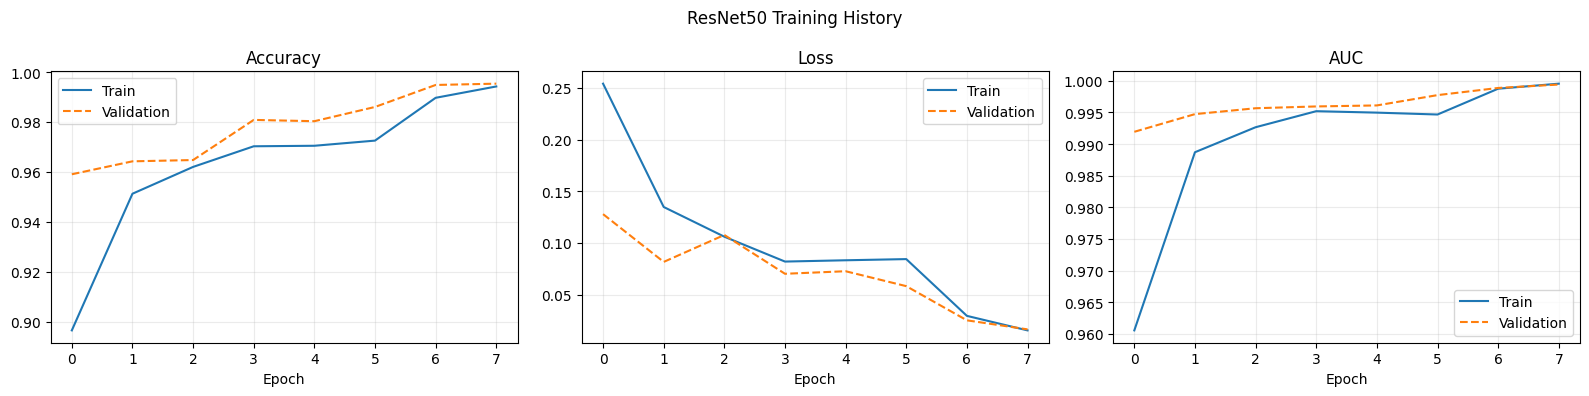

In [15]:
# Plot training curves across both phases
def merge_history(*histories):
    out = {}
    for h in histories:
        if h is not None:
            for key, values in h.history.items():
                out.setdefault(key, []).extend(values)
    return out

hist = merge_history(history_p1, history_p2)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, metric, title in zip(axes, ["accuracy", "loss", "auc"], ["Accuracy", "Loss", "AUC"]):
    if metric in hist: ax.plot(hist[metric], label="Train")
    if "val_" + metric in hist: ax.plot(hist["val_" + metric], "--", label="Validation")
    ax.set_title(title); ax.set_xlabel("Epoch"); ax.grid(True, alpha=0.25); ax.legend()
plt.suptitle("ResNet50 Training History")
plt.tight_layout()
plt.show()

262/262 ━━━━━━━━━━━━━━━━━━━━ 367s 1s/step - accuracy: 0.9775 - auc: 0.9947 - loss: 0.0724 - precision: 0.9905 - recall: 0.9818
262/262 ━━━━━━━━━━━━━━━━━━━━ 349s 1s/step
               precision    recall  f1-score   support

Non-Tumourous     0.9231    0.9588    0.9406       388
    Tumourous     0.9905    0.9818    0.9862      1705

     accuracy                         0.9775      2093
    macro avg     0.9568    0.9703    0.9634      2093
 weighted avg     0.9780    0.9775    0.9777      2093

Confusion matrix (rows=actual, columns=predicted):
 [[ 372   16]
 [  31 1674]]


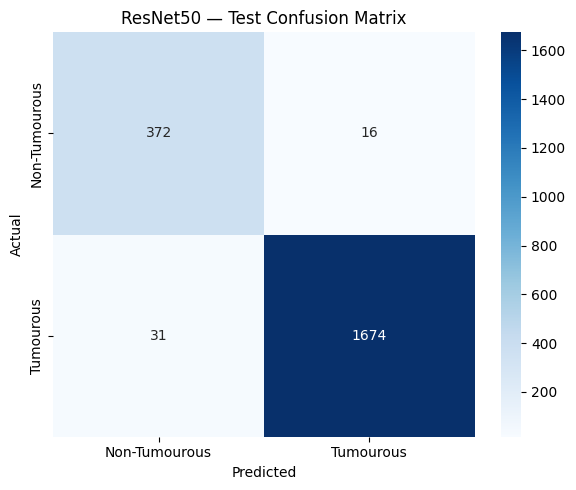

,Model,Accuracy,Precision,Recall,F1-score,Specificity,ROC-AUC,PR-AUC,Test loss,Training time (minutes),Test samples
0,ResNet50,0.977544,0.990533,0.981818,0.986156,0.958763,0.996197,0.999189,0.072398,163.532118,2093


Saved ResNet50 metrics.


In [16]:
# Final test evaluation (held-out test split)
if os.path.isfile(BEST_PATH):
    best_model = tf.keras.models.load_model(BEST_PATH)
elif os.path.isfile(PHASE1_PATH):
    best_model = tf.keras.models.load_model(PHASE1_PATH)
else:
    raise FileNotFoundError("No ResNet50 checkpoint found; run training cells first.")

test_loss, test_acc, test_prec, test_rec, test_auc_metric = best_model.evaluate(test_ds, verbose=1)
y_true = test_df["label"].to_numpy().astype(int)
y_prob = best_model.predict(test_ds, verbose=1).ravel()
y_pred = (y_prob >= 0.5).astype(int)

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
specificity = tn / (tn + fp) if (tn + fp) else np.nan
f1 = f1_score(y_true, y_pred, zero_division=0)
try: roc_auc = roc_auc_score(y_true, y_prob)
except ValueError: roc_auc = np.nan
try: pr_auc = average_precision_score(y_true, y_prob)
except ValueError: pr_auc = np.nan

print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4, zero_division=0))
print("Confusion matrix (rows=actual, columns=predicted):\n", cm)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.title("ResNet50 — Test Confusion Matrix")
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.tight_layout(); plt.show()

resnet_metrics = {
    "Model": "ResNet50",
    "Accuracy": float(accuracy_score(y_true, y_pred)),
    "Precision": float(precision_score(y_true, y_pred, zero_division=0)),
    "Recall": float(recall_score(y_true, y_pred, zero_division=0)),
    "F1-score": float(f1),
    "Specificity": float(specificity) if np.isfinite(specificity) else np.nan,
    "ROC-AUC": float(roc_auc) if np.isfinite(roc_auc) else np.nan,
    "PR-AUC": float(pr_auc) if np.isfinite(pr_auc) else np.nan,
    "Test loss": float(test_loss),
    "Training time (minutes)": float((phase1_seconds + phase2_seconds)/60),
    "Test samples": int(len(test_df))
}
resnet_metrics_df = pd.DataFrame([resnet_metrics])
display(resnet_metrics_df)
resnet_metrics_df.to_csv(os.path.join(RESULTS_DIR, "resnet50_test_metrics.csv"), index=False)
print("Saved ResNet50 metrics.")

In [17]:
# Build comparison table from real previous model result files
# Supports the B0 notebook's Metric/Score format and one-row metric CSVs.
def as_fraction(value):
    value = pd.to_numeric(value, errors="coerce")
    if pd.isna(value): return np.nan
    value = float(value)
    return value / 100.0 if value > 1 else value

def first_col(columns, candidates):
    norm_cols = {str(c).lower().replace("_", " ").strip(): c for c in columns}
    for term in candidates:
        for norm, original in norm_cols.items():
            if term in norm: return original
    return None

def read_metrics(path, model_name):
    if not os.path.isfile(path):
        print("Not found:", path)
        return None
    df = pd.read_csv(path)
    if df.empty:
        print("Empty metrics file:", path)
        return None

    if {"Metric", "Score"}.issubset(df.columns):
        vals = {str(r["Metric"]).lower(): as_fraction(r["Score"]) for _, r in df.iterrows()}
        def metric_value(terms):
            return next((v for k, v in vals.items() if any(t in k for t in terms)), np.nan)
        acc = metric_value(["accuracy"])
        prec = metric_value(["precision"])
        rec = metric_value(["recall", "sensitivity"])
        f1v = metric_value(["f1"])
        auc = metric_value(["roc-auc", "roc auc", "auc"])
        samples = np.nan
    else:
        row = df.iloc[0].to_dict()
        def get(terms):
            c = first_col(df.columns, terms)
            return as_fraction(row[c]) if c else np.nan
        acc = get(["accuracy"])
        prec = get(["precision"])
        rec = get(["recall", "sensitivity"])
        f1v = get(["f1"])
        auc = get(["roc auc", "roc-auc", "auc"])
        c_samples = first_col(df.columns, ["test samples", "sample count"])
        samples = row[c_samples] if c_samples else np.nan

    if not np.isfinite(acc):
        print("Could not detect accuracy; skipping:", path)
        return None
    if not np.isfinite(f1v) and np.isfinite(prec) and np.isfinite(rec) and prec + rec > 0:
        f1v = 2 * prec * rec / (prec + rec)
    return {
        "Model": model_name, "Accuracy": acc, "Precision": prec,
        "Recall": rec, "F1-score": f1v, "ROC-AUC": auc,
        "Training time (minutes)": np.nan, "Test samples": samples
    }

comparison_rows = [resnet_metrics.copy()]
prior_files = [
    (os.path.join(RESULTS_DIR, "efficientnet_metrics.csv"), "EfficientNetB0"),
    (os.path.join(RESULTS_DIR, "efficientnet_b0_test_metrics.csv"), "EfficientNetB0"),
    (os.path.join(RESULTS_DIR, "efficientnetv2s_test_metrics.csv"), "EfficientNetV2S"),
    (os.path.join(RESULTS_DIR, "model_comparison_v2s.csv"), None),
    (os.path.join(RESULTS_DIR, "test_metrics.csv"), "Custom CNN"),
]
seen = {"ResNet50"}
for path, name in prior_files:
    if name is None:
        if os.path.isfile(path):
            old = pd.read_csv(path)
            if "Model" in old.columns:
                for _, row in old.iterrows():
                    old_name = str(row["Model"])
                    if old_name in seen: continue
                    row_df = pd.DataFrame([row])
                    temp_path = os.path.join(RESULTS_DIR, "_temp_compare_row.csv")
                    row_df.to_csv(temp_path, index=False)
                    item = read_metrics(temp_path, old_name)
                    if item:
                        comparison_rows.append(item); seen.add(old_name)
                try: os.remove(temp_path)
                except Exception: pass
        continue
    if name in seen: continue
    item = read_metrics(path, name)
    if item:
        comparison_rows.append(item); seen.add(name)

comparison_df = pd.DataFrame(comparison_rows).drop_duplicates("Model", keep="first")

# Save master table so future models can be added to the comparison.
comparison_path = os.path.join(RESULTS_DIR, "model_comparison_resnet50.csv")
comparison_df.to_csv(comparison_path, index=False)
display(comparison_df.style.format({
    "Accuracy": "{:.4f}", "Precision": "{:.4f}", "Recall": "{:.4f}",
    "F1-score": "{:.4f}", "ROC-AUC": "{:.4f}",
    "Training time (minutes)": "{:.1f}"
}))
print("Comparison saved to:", comparison_path)
print("Only real available metric files are included. Confirm all models used the same test split before interpreting the comparison.")

,Model,Accuracy,Precision,Recall,F1-score,Specificity,ROC-AUC,PR-AUC,Test loss,Training time (minutes),Test samples
0,ResNet50,0.9775,0.9905,0.9818,0.9862,0.958763,0.9962,0.999189,0.072398,163.5,2093.000000
1,EfficientNetB0,0.9618,0.9939,0.9589,0.9761,nan,0.9912,nan,nan,nan,nan
2,EfficientNetV2S,0.9551,0.9939,0.9507,0.9718,nan,0.9917,nan,nan,nan,2093.000000
3,Custom CNN,0.9479,0.9744,0.9613,0.9678,nan,nan,nan,nan,nan,nan


Comparison saved to: /content/drive/MyDrive/Brain_Tumor_CNN_Project/results/model_comparison_resnet50.csv
Only real available metric files are included. Confirm all models used the same test split before interpreting the comparison.


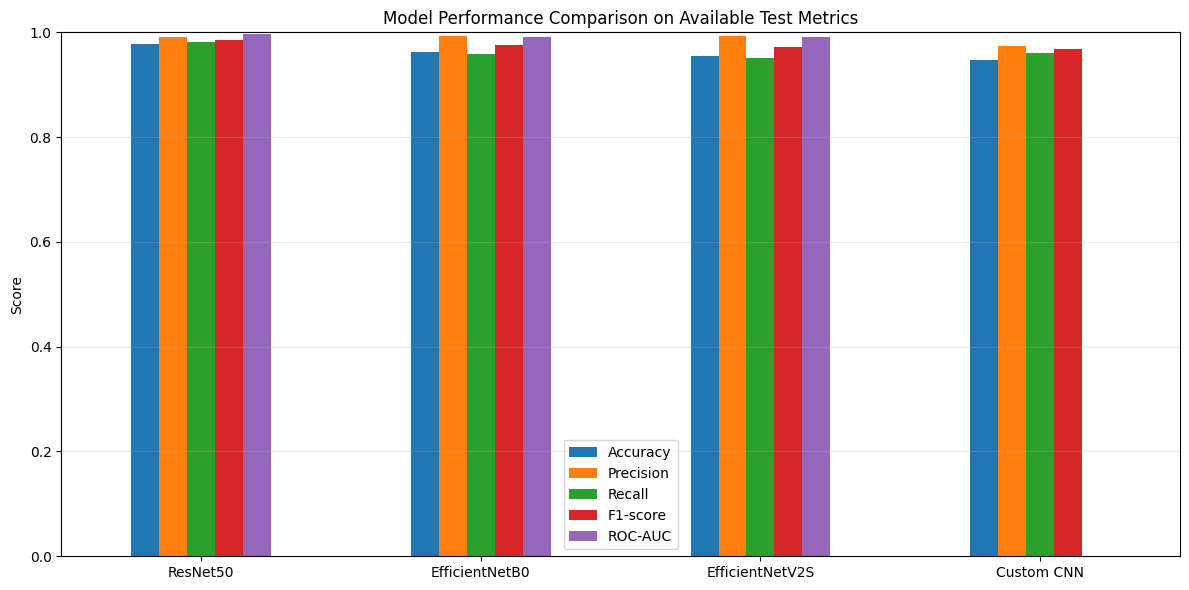

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,Accuracy change vs ResNet50 (pp)
0,ResNet50,0.9775,0.9905,0.9818,0.9862,0.9962,+0.00
1,EfficientNetB0,0.9618,0.9939,0.9589,0.9761,0.9912,-1.58
2,EfficientNetV2S,0.9551,0.9939,0.9507,0.9718,0.9917,-2.25
3,Custom CNN,0.9479,0.9744,0.9613,0.9678,nan,-2.96


In [18]:
# Performance comparison chart and accuracy progress table
plot_metrics = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]
available = [m for m in plot_metrics if m in comparison_df and comparison_df[m].notna().any()]
if available:
    ax = comparison_df.set_index("Model")[available].plot(
        kind="bar", figsize=(12, 6), ylim=(0, 1), rot=0
    )
    ax.set_title("Model Performance Comparison on Available Test Metrics")
    ax.set_ylabel("Score")
    ax.set_xlabel("")
    ax.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()

# Progress table relative to the first listed model (descriptive, not causal).
if "Accuracy" in comparison_df:
    progress_df = comparison_df[["Model", "Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]].copy()
    baseline = progress_df["Accuracy"].iloc[0]
    progress_df["Accuracy change vs ResNet50 (pp)"] = (progress_df["Accuracy"] - baseline) * 100
    display(progress_df.style.format({
        "Accuracy": "{:.4f}", "Precision": "{:.4f}", "Recall": "{:.4f}",
        "F1-score": "{:.4f}", "ROC-AUC": "{:.4f}",
        "Accuracy change vs ResNet50 (pp)": "{:+.2f}"
    }))

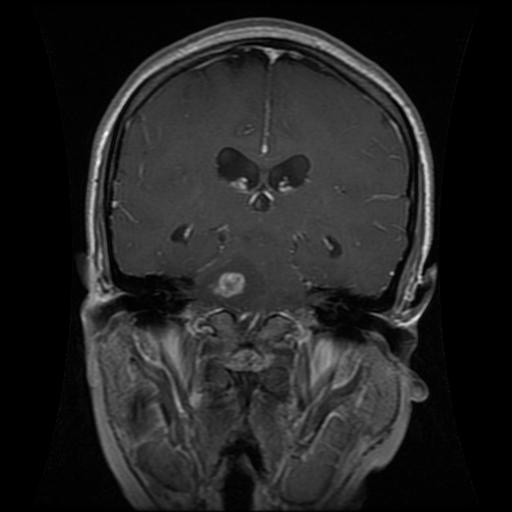

Image: 1049.jpg
Actual: Tumourous
Predicted: Tumourous
Tumour probability: 1.0000


In [19]:
# Example prediction from the held-out test set
from IPython.display import display
from PIL import Image

sample_idx = 0
sample_row = test_df.iloc[sample_idx]
display(Image.open(sample_row["image_path"]).convert("RGB"))
print("Image:", os.path.basename(sample_row["image_path"]))
print("Actual:", CLASS_NAMES[int(y_true[sample_idx])])
print("Predicted:", CLASS_NAMES[int(y_pred[sample_idx])])
print("Tumour probability:", f"{float(y_prob[sample_idx]):.4f}")